# Echo Hiding — Proof of Concept
Python prototype of echo-hiding steganography (Gruhl, Bender & Lu): each window is convolved with
$h_b(n)=\delta(n)+a_b\,\delta(n-t_b)$, windows (with $\sin^2$ crossfades) are merged with overlap-add, and bits are recovered from the
cepstrum autocorrelation $R_{cc}(n)=\mathcal{F}^{-1}\{\ln^2|\mathcal{F}\{x(n)\}|\}$.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

FS = 44100
DELAY0_US, DELAY1_US = 1000, 1500   # echo delay for bit 0 / bit 1
ATT0_PCT, ATT1_PCT = 40, 40         # echo amplitude, % of the original
WIN_MULT = 10                       # window length = WIN_MULT * max delay
THR = 3.0                           # min robust z-score of an echo peak
GAP = 13                            # echo-less windows that end the message (~195 ms)
CHANNEL = 0                         # 0 = left, 1 = right

C0, C1 = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(0)

## Test audio
Any CD-quality WAV (44.1 kHz, 16-bit, stereo) can be dropped in as `input.wav`; otherwise a synthetic clip is generated.

In [2]:
def synth_music(dur=30.0, fs=FS):
    n = int(dur * fs)
    t = np.arange(n) / fs
    out = np.zeros((n, 2))
    scale = 220 * 2 ** (np.array([0, 2, 4, 5, 7, 9, 11, 12]) / 12)
    step = int(0.25 * fs)
    for s in range(0, n, step):
        tt = t[:min(2 * step, n - s)]
        f0, pan = rng.choice(scale), rng.uniform(0.3, 0.7)
        note = sum(np.sin(2 * np.pi * k * f0 * tt) / k for k in range(1, 8)) * np.exp(-6 * tt)
        out[s:s + len(tt)] += note[:, None] * [1 - pan, pan]
    out += 0.15 * rng.standard_normal((n, 2)) * np.exp(-60 * (t % 0.125))[:, None]  # hi-hat
    out += 0.01 * rng.standard_normal((n, 2))
    return (0.6 * 32767 * out / np.abs(out).max()).astype(np.int16)


src = Path("input.wav")
if not src.exists():
    wavfile.write(src, FS, synth_music())
fs, audio = wavfile.read(src)
assert fs == FS and audio.dtype == np.int16 and audio.ndim == 2
x = audio[:, CHANNEL].astype(float)
print(f"{src}: {len(audio) / fs:.1f} s, {audio.shape[1]} ch, {audio.dtype}")

input.wav: 30.0 s, 2 ch, int16


## Encoder

In [3]:
d = (round(DELAY0_US * FS / 1e6), round(DELAY1_US * FS / 1e6))
a = (ATT0_PCT / 100, ATT1_PCT / 100)
L = WIN_MULT * max(d)
print(f"delays = {d} samples, window = {L} samples ({1e3 * L / FS:.1f} ms), rate = {FS / L:.1f} bit/s")


def kernel(delay, amp):
    h = np.zeros(delay + 1)
    h[0], h[delay] = 1.0, amp
    return h


def encode(x, bits, d=d, a=a, L=L, R=None):
    R = L if R is None else R               # crossfade length (even, <= L); 0 = abrupt switching
    h = [kernel(d[0], a[0]), kernel(d[1], a[1])]
    y = np.zeros(len(x) + max(d))
    nw = -(-len(x) // L)
    for k in range(nw):
        s, e = k * L, (k + 1) * L
        lo, hi = max(0, s - R // 2), min(len(x), e + R // 2)
        n = np.arange(lo, hi)
        w = np.ones(hi - lo)                # sin^2 ramps: overlapping windows sum to one
        if R and k > 0:
            m = n < s + R // 2
            w[m] = np.sin(np.pi / 2 * (n[m] - (s - R // 2) + 0.5) / R) ** 2
        if R and k < nw - 1:
            m = n >= e - R // 2
            w[m] = np.cos(np.pi / 2 * (n[m] - (e - R // 2) + 0.5) / R) ** 2
        v = x[lo:hi] * w
        yk = np.convolve(v, h[bits[k]]) if k < len(bits) else v
        y[lo:lo + len(yk)] += yk  # overlap-add: ramps and the N-1 tail spill into the neighbours
    return y[:len(x)]


for b in (0, 1):
    assert np.allclose(encode(x, [b] * (len(x) // L + 1)), np.convolve(x, kernel(d[b], a[b]))[:len(x)])
print("overlap-add == full-signal convolution")

delays = (44, 66) samples, window = 660 samples (15.0 ms), rate = 66.8 bit/s


overlap-add == full-signal convolution


## Decoder
Windows are scaled to a fixed level so $c(0)\gg0$ and $R_{cc}(t_b)\approx 2\,c(0)\,c(t_b)$ peaks at the echo delay.

In [4]:
def rcc(v):
    v = 2**15 * v / (np.sqrt(np.mean(v**2)) + 1e-12)
    C = np.log(np.abs(np.fft.rfft(v * np.hanning(len(v)))) + 1e-12)
    return np.fft.irfft(C**2, n=len(v))


def classify(r, d=d):
    ref = r[max(d) // 2 + 1:3 * max(d)]
    med = np.median(ref)
    z = (r[list(d)] - med) / (np.median(np.abs(ref - med)) + 1e-12)  # robust z-score
    return int(np.argmax(z)), z.max()


def decode(y, d=d, L=L):
    out = np.array([classify(rcc(y[s:s + L]), d) for s in range(0, len(y) - L + 1, L)])
    return out[:, 0].astype(int), out[:, 1]

## Metadata

In [5]:
KEYS = {"title": "Title", "artist": "Artist", "author": "Author", "album": "Album",
        "year": "Year", "guest": "Guest artist", "producer": "Producer"}


def pack(meta):
    text = "".join(f"{k}={v}\n" for k, v in meta.items())
    return np.unpackbits(np.frombuffer(text.encode(), np.uint8))


def unpack(bits, z, thr=THR, gap=GAP):
    quiet = np.convolve((z < thr).astype(float), np.ones(gap), "valid") == gap
    end = np.argmax(quiet) if quiet.any() else len(bits)  # message ends at the first echo-less run
    text = np.packbits(bits[:end - end % 8]).tobytes().decode(errors="replace")
    for line in filter(None, text.split("\n")):
        key, _, val = line.partition("=")
        if key in KEYS:
            print(f"{KEYS[key]}: {val}")
        else:
            print(f"WARNING: unknown metadata {line!r}", file=sys.stderr)

## End to end

In [6]:
meta = {"title": "Echo Song", "artist": "The Cepstrals", "author": "J. Doe", "album": "LTI Hits",
        "year": "2026", "guest": "A. Delay", "producer": "M. Convolve",
        "mood": "calm"}  # unknown key -> stderr
bits = pack(meta)
assert len(bits) <= len(x) // L, "audio too short for this payload"

enc = audio.copy()
enc[:, CHANNEL] = np.clip(np.round(encode(x, bits)), -32768, 32767)
wavfile.write("encoded.wav", FS, enc)

_, rx = wavfile.read("encoded.wav")
dec, z = decode(rx[:, CHANNEL].astype(float))
has = z >= THR
print(f"payload: {len(bits)} bits in {len(bits) * L / FS:.1f} s")
print(f"recovery rate: {np.mean(dec[:len(bits)] == bits):.1%}")
print(f"echo detected: {has[:len(bits)].mean():.1%} of payload windows, {has[len(bits):].mean():.1%} of empty windows\n")
unpack(dec, z)

payload: 976 bits in 14.6 s
recovery rate: 100.0%
echo detected: 99.9% of payload windows, 1.8% of empty windows

Title: Echo Song
Artist: The Cepstrals
Author: J. Doe
Album: LTI Hits
Year: 2026
Guest artist: A. Delay
Producer: M. Convolve


In [7]:
print("original / encoded (first 10 s)")
display(Audio(x[:10 * FS] / 32768, rate=FS, normalize=False),
        Audio(rx[:10 * FS, CHANNEL] / 32768, rate=FS, normalize=False))

original / encoded (first 10 s)


## Impulse responses and cepstrum autocorrelation

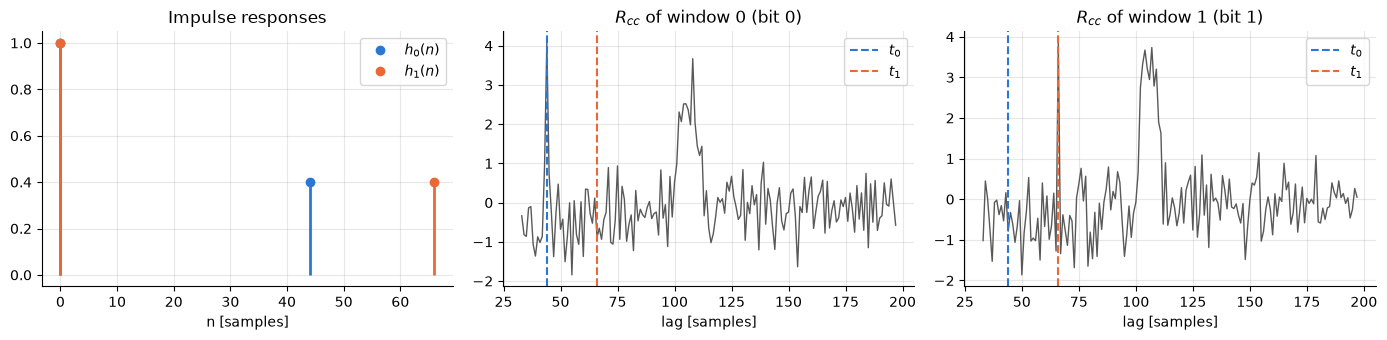

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for b, c in ((0, C0), (1, C1)):
    n = np.flatnonzero(kernel(d[b], a[b]))
    ax[0].vlines(n, 0, kernel(d[b], a[b])[n], color=c, lw=2)
    ax[0].plot(n, kernel(d[b], a[b])[n], "o", color=c, label=f"$h_{b}(n)$")
ax[0].set(title="Impulse responses", xlabel="n [samples]")
ax[0].legend()

lags = np.arange(max(d) // 2, 3 * max(d))
for i, b in enumerate((0, 1), start=1):
    k = np.flatnonzero(bits == b)[0]
    r = rcc(rx[k * L:(k + 1) * L, CHANNEL].astype(float))
    ax[i].plot(lags, r[lags], color="0.35", lw=1)
    ax[i].axvline(d[0], color=C0, ls="--", lw=1.5, label="$t_0$")
    ax[i].axvline(d[1], color=C1, ls="--", lw=1.5, label="$t_1$")
    ax[i].set(title=f"$R_{{cc}}$ of window {k} (bit {b})", xlabel="lag [samples]")
    ax[i].legend()
fig.tight_layout()

## Parameter sweeps

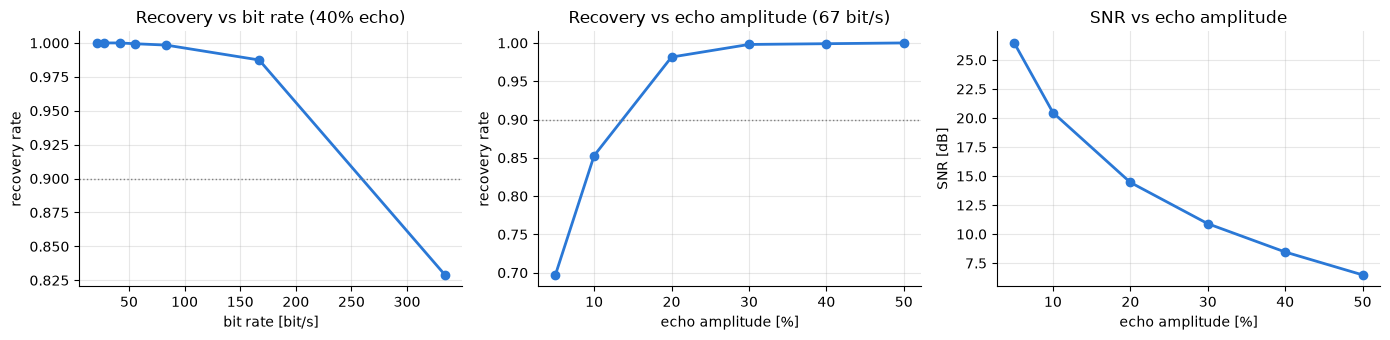

In [9]:
xs = x[:30 * FS]


def trial(att_pct=ATT0_PCT, mult=WIN_MULT):
    Lw = mult * max(d)
    b = rng.integers(0, 2, len(xs) // Lw)
    y = encode(xs, b, a=(att_pct / 100,) * 2, L=Lw)
    snr = 10 * np.log10(np.sum(xs**2) / np.sum((y - xs)**2))
    return np.mean(decode(y, L=Lw)[0] == b), snr


mults = [2, 4, 8, 12, 16, 24, 32]
atts = [5, 10, 20, 30, 40, 50]
rec_m = [trial(mult=m)[0] for m in mults]
rec_a, snr_a = zip(*[trial(att_pct=p) for p in atts])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot([FS / (m * max(d)) for m in mults], rec_m, "o-", color=C0, lw=2)
ax[0].set(title=f"Recovery vs bit rate ({ATT0_PCT}% echo)", xlabel="bit rate [bit/s]", ylabel="recovery rate")
ax[1].plot(atts, rec_a, "o-", color=C0, lw=2)
ax[1].set(title=f"Recovery vs echo amplitude ({FS / L:.0f} bit/s)", xlabel="echo amplitude [%]", ylabel="recovery rate")
for axi in ax[:2]:
    axi.axhline(0.9, color="0.5", ls=":", lw=1)
ax[2].plot(atts, snr_a, "o-", color=C0, lw=2)
ax[2].set(title="SNR vs echo amplitude", xlabel="echo amplitude [%]", ylabel="SNR [dB]")
fig.tight_layout()

## Pruebas end to end
Simplificacion de resultados para evaluar todas las opciones en una sola celda. 

976 bits (122 bytes); t = (44, 66) muestras; a = (0.4, 0.4); L = 660 (66.8 bit/s)



  Sintética listo


  Rock listo


  Piano moderno listo


  Piano clásico listo


  Electrónica listo


  Voz listo

Extremo a extremo (976 bits, parámetros por defecto)
Pista              Recup.%    Errores    EcoDet%     Falso%  Metadatos    Recorte       PESQ  PESQ cod.
Sintética            100.0          0       99.9        1.8        7/7          0       4.29       4.06
Rock                  99.8          2       99.5        6.8        5/7        207        nan        nan
Piano moderno         99.3          7       88.8        0.8        3/7          3       4.44       4.30
Piano clásico         99.7          3      100.0        8.2        6/7          0       4.47       4.36
Electrónica           99.8          2       98.9       24.2        5/7          0       4.52       3.35
Voz                   96.4         35       88.8       10.0        0/7          0       4.50       4.43

Salida de error de unpack por pista:
  Sintética: ["WARNING: unknown metadata 'mood=calm'"]
  Rock: ["WARNING: unknown metadata 'auth\\x7fr=J. Doe'", "WARNING: unknown metadata 'mood=calm'", "WARNING: unkn

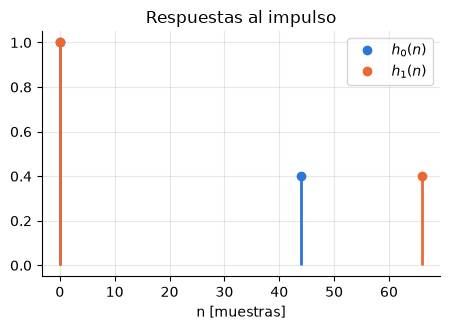

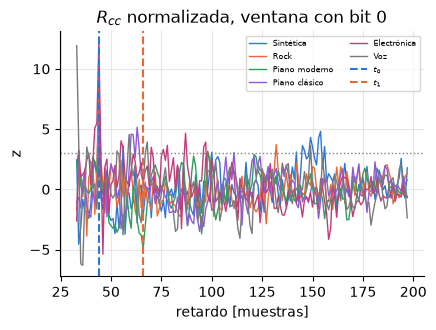

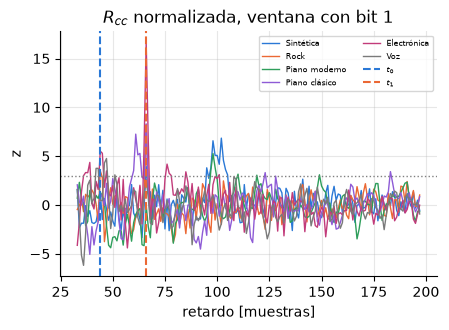

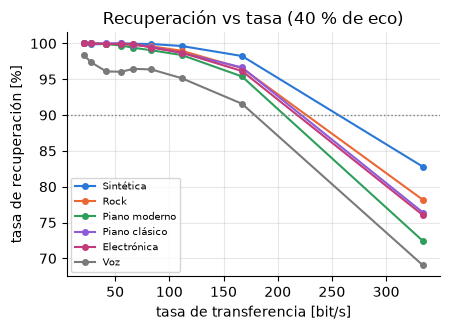

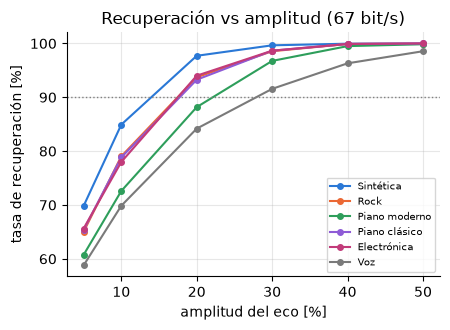

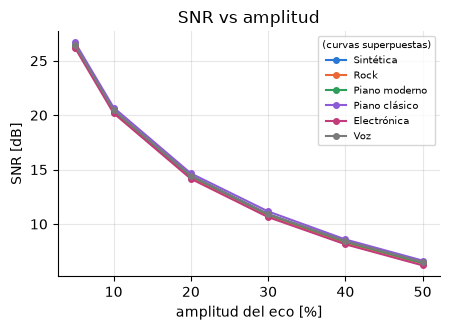

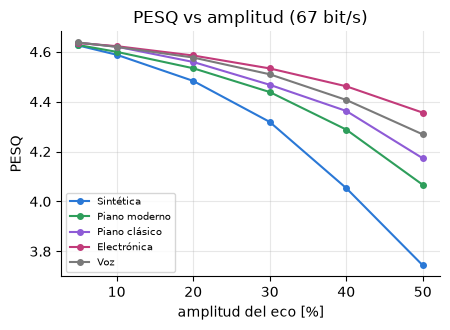

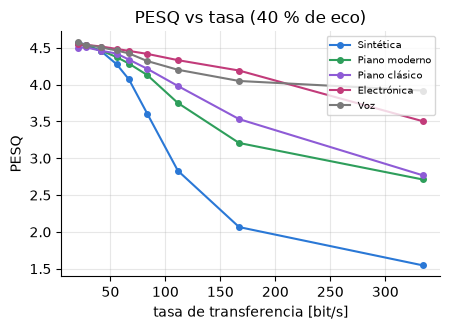

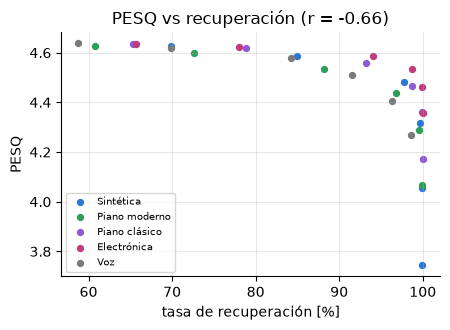

In [10]:
# ---------------------------------------------------------------------------
# Evaluación de todas las pistas en una sola celda:
#   1) extremo a extremo con los parámetros por defecto (+ PESQ)
#   2) respuestas al impulso y autocorrelación del cepstro
#   3) barridos de amplitud y de tasa (recuperación, SNR y PESQ)
# Requiere las celdas de configuración, encoder, decoder y metadata.
# ---------------------------------------------------------------------------
import contextlib
import io

from pesq import pesq, PesqError
from scipy.signal import resample_poly
from scipy.stats import pearsonr, spearmanr

TRACKS = {                                   # nombre en las figuras -> archivo
    "Sintética":     "input.wav",
    "Rock":          "../audio/rock_indie.wav",
    "Piano moderno": "../audio/clasica_moderna_marmixer.wav",
    "Piano clásico": "../audio/clasica_chopin.wav",
    "Electrónica":   "../audio/house_aurec.wav",
    "Voz":           "../audio/voz_narracion.wav",
}
META = {"title": "Echo Song", "artist": "The Cepstrals", "author": "J. Doe", "album": "LTI Hits",
        "year": "2026", "guest": "A. Delay", "producer": "M. Convolve",
        "mood": "calm"}                      # clave desconocida -> stderr (R50, R51)
ATTS = [5, 10, 20, 30, 40, 50]               # barrido de amplitud [%]
MULTS = [2, 4, 6, 8, 10, 12, 16, 24, 32]            # barrido de ventana (L = mult * t_max)
NREP = 3                                     # repeticiones por punto del barrido (mediana)
OUT = Path("../Reporte/images/todas")
OUT.mkdir(parents=True, exist_ok=True)
COLORS = dict(zip(TRACKS, ["#2a78d6", "#eb6834", "#2e9e5b", "#8e5bd6", "#c23b7a", "#7a7a7a"]))


def pesq_wb(ref, deg):
    """PESQ de banda ancha: remuestrea 44.1 kHz -> 16 kHz (160/441) y escala a [-1, 1]."""
    r = resample_poly(ref, 160, 441) / 32768
    g = resample_poly(deg, 160, 441) / 32768
    try:
        return pesq(16000, r, g, "wb")
    except PesqError:                        # PESQ no detecta actividad en la pista
        return np.nan


def snr_db(x, y):
    return 10 * np.log10(np.sum(x**2) / np.sum((y - x)**2))


def zcurve(r, d=d):
    """R_cc expresada como el z-score robusto que usa classify, para comparar pistas."""
    ref = r[max(d) // 2 + 1:3 * max(d)]
    med = np.median(ref)
    return (r - med) / (np.median(np.abs(ref - med)) + 1e-12)


def run(x, att_pct=ATT0_PCT, mult=WIN_MULT, use_pesq=True):
    """Bits aleatorios con la configuración dada; mediana de NREP repeticiones."""
    aa = (att_pct / 100,) * 2
    Lw = mult * max(d)
    rec, snr, pq = [], [], []
    for _ in range(NREP):
        b = rng.integers(0, 2, len(x) // Lw)
        y = np.clip(np.round(encode(x, b, a=aa, L=Lw)), -32768, 32767)
        rec.append(np.mean(decode(y, L=Lw)[0] == b))
        snr.append(snr_db(x, y))
        pq.append(pesq_wb(x, y) if use_pesq else np.nan)
    return {"rec": np.median(rec), "snr": np.median(snr), "rate": FS / Lw,
            "pesq": np.nan if np.all(np.isnan(pq)) else np.nanmedian(pq)}


bits = pack(META)
expected = [f"{KEYS[k]}: {v}" for k, v in META.items() if k in KEYS]
print(f"{len(bits)} bits ({len(bits) // 8} bytes); t = {d} muestras; a = {a}; "
      f"L = {L} ({FS / L:.1f} bit/s)\n")

e2e, curves, sweeps = {}, {}, {}
for name, path in TRACKS.items():
    fs_, au = wavfile.read(path)
    assert fs_ == FS and au.dtype == np.int16 and au.ndim == 2, path
    xt = au[:, CHANNEL].astype(float)
    nwin = len(xt) // L
    assert len(bits) + GAP <= nwin, f"{name}: {len(bits)} bits + {GAP} no caben en {nwin} ventanas"

    # 1) extremo a extremo (mismo flujo que la celda "End to end")
    yf = encode(xt, bits)
    y = np.clip(np.round(yf), -32768, 32767)
    dec, z = decode(y)
    nb = len(bits)
    has = z >= THR
    out, err = io.StringIO(), io.StringIO()
    with contextlib.redirect_stdout(out), contextlib.redirect_stderr(err):
        unpack(dec, z)
    found = out.getvalue().splitlines()
    n = nb * L                               # tramo con eco
    ceil = pesq_wb(xt, xt)                   # ≈ 4.64; nan si PESQ no evalúa la pista
    e2e[name] = {
        "rec": np.mean(dec[:nb] == bits), "err": int(np.sum(dec[:nb] != bits)),
        "det": has[:nb].mean(), "false": has[nb:].mean(),
        "meta": sum(line in found for line in expected),
        "clip": int(np.sum((yf > 32767) | (yf < -32768))),
        "pesq_full": pesq_wb(xt, y), "pesq_enc": pesq_wb(xt[:n], y[:n]),
        "stderr": err.getvalue().strip().splitlines(),
    }

    # 2) R_cc de la ventana con más energía para cada bit (evita ventanas en silencio)
    rms = np.array([np.sqrt(np.mean(xt[k * L:(k + 1) * L]**2)) for k in range(nb)])
    curves[name] = {}
    for b in (0, 1):
        k = np.flatnonzero(bits == b)[np.argmax(rms[bits == b])]
        curves[name][b] = zcurve(rcc(y[k * L:(k + 1) * L]))

    # 3) barridos con bits aleatorios
    ok = not np.isnan(ceil)
    sweeps[name] = {"att":  [run(xt, att_pct=p, use_pesq=ok) for p in ATTS],
                    "mult": [run(xt, mult=m, use_pesq=ok) for m in MULTS]}
    print(f"  {name} listo")


def col(name, key, field):
    return np.array([r[field] for r in sweeps[name][key]])


HAS_PESQ = [nm for nm in TRACKS if not np.all(np.isnan(col(nm, "att", "pesq")))]

# --- Tabla 1: extremo a extremo ---------------------------------------------
print(f"\nExtremo a extremo ({nb} bits, parámetros por defecto)")
hdr = ["Recup.%", "Errores", "EcoDet%", "Falso%", "Metadatos", "Recorte", "PESQ", "PESQ cod."]
print(f"{'Pista':<15}" + "".join(f"{h:>11}" for h in hdr))
for name, r in e2e.items():
    print(f"{name:<15}{100 * r['rec']:>11.1f}{r['err']:>11}{100 * r['det']:>11.1f}"
          f"{100 * r['false']:>11.1f}{r['meta']:>9}/{len(expected)}{r['clip']:>11}"
          f"{r['pesq_full']:>11.2f}{r['pesq_enc']:>11.2f}")
print("\nSalida de error de unpack por pista:")
for name, r in e2e.items():
    print(f"  {name}: {r['stderr']}")

# --- Tabla 2: barridos -------------------------------------------------------
def table(key, label, values):
    print(f"\n{label}   (celdas: recuperación % / PESQ)")
    print(f"{'':>15}" + "".join(f"{str(v):>15}" for v in values))
    for name in TRACKS:
        print(f"{name:>15}" + "".join(f"{f'{100 * r['rec']:.1f} / {r['pesq']:.2f}':>15}"
                                      for r in sweeps[name][key]))

table("att", f"Amplitud [%] a {FS / L:.1f} bit/s", ATTS)
table("mult", f"Tasa [bit/s] con {ATT0_PCT} %", [f"{FS / (m * max(d)):.1f}" for m in MULTS])

# --- Tabla 3: correlaciones (A30, A31) ---------------------------------------
def corr(xv, yv):
    ok = ~(np.isnan(xv) | np.isnan(yv))
    if ok.sum() < 3:
        return np.nan, np.nan
    return pearsonr(xv[ok], yv[ok])[0], spearmanr(xv[ok], yv[ok])[0]

pairs = {"recuperación–PESQ": ("att", "rec", "pesq"),
         "tasa–PESQ": ("mult", "rate", "pesq"),
         "tasa–recuperación": ("mult", "rate", "rec")}
print("\nCorrelaciones (Pearson r / Spearman ρ)")
print(f"{'':>15}" + "".join(f"{p:>22}" for p in pairs))
for name in [*TRACKS, "Todas"]:
    names = list(TRACKS) if name == "Todas" else [name]
    cells = []
    for key, fx, fy in pairs.values():
        xv = np.concatenate([col(nm, key, fx) for nm in names])
        yv = np.concatenate([col(nm, key, fy) for nm in names])
        p, s = corr(xv, yv)
        cells.append(f"{p:+.2f} / {s:+.2f}")
    print(f"{name:>15}" + "".join(f"{c:>22}" for c in cells))
r_rec_pesq = corr(np.concatenate([col(nm, "att", "rec") for nm in TRACKS]),
                  np.concatenate([col(nm, "att", "pesq") for nm in TRACKS]))[0]

# --- Figuras: un panel por archivo, 300 dpi -----------------------------------
FIG = (4.6, 3.4)                             # misma proporción que las imágenes del artículo


def panel(fname, title, xlabel, ylabel=None, draw=None, legend=dict(fontsize=7)):
    """Crea una figura de un solo panel, la dibuja con `draw(ax)` y la guarda en OUT."""
    fig, ax = plt.subplots(figsize=FIG)
    draw(ax)
    ax.set(title=title, xlabel=xlabel, **({"ylabel": ylabel} if ylabel else {}))
    if legend is not None:
        ax.legend(**legend)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=300)
    plt.show()


def draw_kernels(ax):
    for b, c in ((0, C0), (1, C1)):
        h = kernel(d[b], a[b])
        nz = np.flatnonzero(h)
        ax.vlines(nz, 0, h[nz], color=c, lw=2)
        ax.plot(nz, h[nz], "o", color=c, label=f"$h_{b}(n)$")


def draw_rcc(b):
    lags = np.arange(max(d) // 2, 3 * max(d))
    def draw(ax):
        for name in TRACKS:
            ax.plot(lags, curves[name][b][lags], color=COLORS[name], lw=1, label=name)
        ax.axvline(d[0], color=C0, ls="--", lw=1.5, label="$t_0$")
        ax.axvline(d[1], color=C1, ls="--", lw=1.5, label="$t_1$")
        ax.axhline(THR, color="0.5", ls=":", lw=1)
    return draw


def draw_lines(names, key, fx, fy, scale=1, ref90=False):
    def draw(ax):
        for name in names:
            xv = ATTS if fx == "att" else col(name, key, fx)
            ax.plot(xv, scale * col(name, key, fy), color=COLORS[name], lw=1.5,
                    marker="o", ms=4, label=name)
        if ref90:
            ax.axhline(90, color="0.5", ls=":", lw=1)
    return draw


def draw_scatter(ax):
    for name in HAS_PESQ:
        ax.scatter(100 * col(name, "att", "rec"), col(name, "att", "pesq"),
                   color=COLORS[name], s=18, label=name)


panel("respuesta_al_impulso.png", "Respuestas al impulso", "n [muestras]", draw=draw_kernels,
      legend=dict())
for b in (0, 1):
    panel(f"ventana{b}.png", f"$R_{{cc}}$ normalizada, ventana con bit {b}", "retardo [muestras]", "z",
          draw=draw_rcc(b), legend=dict(fontsize=6, ncol=2, loc="upper right"))
panel("recuperacion_vs_tasa.png", f"Recuperación vs tasa ({ATT0_PCT} % de eco)",
      "tasa de transferencia [bit/s]", "tasa de recuperación [%]",
      draw=draw_lines(TRACKS, "mult", "rate", "rec", 100, True), legend=dict(fontsize=7, loc="lower left"))
panel("recuperacion_vs_amplitud.png", f"Recuperación vs amplitud ({FS / L:.0f} bit/s)",
      "amplitud del eco [%]", "tasa de recuperación [%]",
      draw=draw_lines(TRACKS, "att", "att", "rec", 100, True), legend=dict(fontsize=7, loc="lower right"))
panel("snr_vs_ampitud.png", "SNR vs amplitud", "amplitud del eco [%]", "SNR [dB]",
      draw=draw_lines(TRACKS, "att", "att", "snr"),
      legend=dict(fontsize=7, loc="upper right", title="(curvas superpuestas)", title_fontsize=7))
panel("PESQ_vs_amplitud.png", f"PESQ vs amplitud ({FS / L:.0f} bit/s)", "amplitud del eco [%]", "PESQ",
      draw=draw_lines(HAS_PESQ, "att", "att", "pesq"), legend=dict(fontsize=7, loc="lower left"))
panel("PESQ_vs_tasa.png", f"PESQ vs tasa ({ATT0_PCT} % de eco)", "tasa de transferencia [bit/s]", "PESQ",
      draw=draw_lines(HAS_PESQ, "mult", "rate", "pesq"), legend=dict(fontsize=7, loc="upper right"))
panel("PESQ_vs_recuperacion.png", f"PESQ vs recuperación (r = {r_rec_pesq:+.2f})",
      "tasa de recuperación [%]", "PESQ", draw=draw_scatter, legend=dict(fontsize=7, loc="lower left"))